<a href="https://colab.research.google.com/github/Nemphisto/METODOS-NUMERICOS/blob/main/Deber_Metodo_Biseccion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deber: Método de bisección — Algoritmo 2.1

**Asignatura:** Métodos Numéricos  
**Tema:** Método de bisección, convergencia, raíces múltiples y aplicaciones  
**Referencia:** Algoritmo 2.1 y Teorema 2.1, según el material de clase.

En este notebook se implementa el método de bisección de forma fiel al algoritmo proporcionado. Se muestran tablas de iteración, se resuelven los ejercicios del deber y se genera la gráfica requerida.

> **Condición indispensable:** la función debe ser continua en el intervalo y satisfacer $f(a)f(b)<0$. El código valida el cambio de signo, pero **la continuidad debe comprobarse matemáticamente**; el cambio de signo por sí solo no basta si existen asíntotas dentro del intervalo.

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.precision", 10)
print("Bibliotecas cargadas correctamente.")

Bibliotecas cargadas correctamente.


## 1. Implementación del Algoritmo 2.1

Para un intervalo inicial $[a,b]$, calculamos $p=a+(b-a)/2$.  
Si $f(p)=0$ o $(b-a)/2<TOL$, devolvemos $p$.  
En caso contrario, si $f(a)f(p)>0$, actualizamos $a=p$ y $f(a)=f(p)$; si no, actualizamos $b=p$.  
Se emplea un número máximo de iteraciones $N_0$ y se informa cuando el algoritmo falla.

La tabla registra los valores **antes de actualizar** el intervalo en cada iteración, exactamente como en los pasos 3 y 4 del algoritmo.

In [3]:
def biseccion(f, a, b, TOL=1e-5, N0=100):
    """Algoritmo 2.1: devuelve (aproximacion, tabla_de_iteraciones).

    Se asume continuidad en [a,b]; se valida cambio estricto de signo.
    Para cada iteración, el criterio de parada es:
        f(p) == 0  O  (b-a)/2 < TOL
    """
    if not callable(f):
        raise TypeError("f debe ser una función.")
    if not isinstance(N0, (int, np.integer)) or isinstance(N0, bool) or N0 < 1:
        raise ValueError("N0 debe ser un entero positivo.")
    a, b, TOL = float(a), float(b), float(TOL)
    if not (math.isfinite(a) and math.isfinite(b) and a < b):
        raise ValueError("Los extremos deben ser finitos y cumplir a < b.")
    if not (math.isfinite(TOL) and TOL > 0):
        raise ValueError("TOL debe ser un número positivo y finito.")

    FA = float(f(a))
    FB = float(f(b))
    if not (math.isfinite(FA) and math.isfinite(FB)):
        raise ValueError("La función no es finita en los extremos.")
    if FA * FB >= 0:
        raise ValueError("Se requiere f(a)*f(b) < 0; revise el intervalo.")

    historial = []
    i = 1  # Paso 1
    while i <= N0:  # Paso 2
        p = a + (b - a) / 2  # Paso 3
        FP = float(f(p))
        if not math.isfinite(FP):
            raise ValueError("f(p) no es finito; compruebe la continuidad.")
        semiancho = (b - a) / 2
        historial.append({
            "i": i, "a": a, "b": b, "p": p,
            "f(a)": FA, "f(p)": FP,
            "f(a)*f(p)": FA * FP, "(b-a)/2": semiancho
        })
        # Paso 4: condición de parada estricta del material
        if FP == 0 or semiancho < TOL:
            return p, pd.DataFrame(historial)
        i += 1  # Paso 5
        if FA * FP > 0:  # Paso 6
            a = p
            FA = FP
        else:
            b = p

    # Paso 7
    raise RuntimeError(f"El método fracasó después de {N0} iteraciones.")

# Prueba de validación de entrada
try:
    biseccion(lambda x: x*x + 1, -1, 1)
except ValueError as error:
    print("Validación correcta:", error)

Validación correcta: Se requiere f(a)*f(b) < 0; revise el intervalo.


## 2. Condiciones y cota de iteraciones

Por el teorema 2.1, si $f$ es continua en $[a,b]$ y $f(a)f(b)<0$, se aproxima una raíz $p$ con

$$|p_n-p|\leq\frac{b-a}{2^n}.$$

Para $f(x)=x^3-x-1$, intervalo $[1,2]$ y precisión $10^{-4}$, se requieren **14 iteraciones** por la cota del teorema. El valor de $p_{14}$ se calcula a continuación.

In [4]:
def f_cubica(x):
    return x**3 - x - 1

n_teorema = math.ceil(math.log2((2 - 1) / 1e-4))
p14, tabla_cubica = biseccion(f_cubica, 1, 2, TOL=1e-4, N0=100)
print("Iteraciones por el teorema:", n_teorema)
print("p aproximado:", p14)
print("Iteraciones ejecutadas por Algoritmo 2.1:", len(tabla_cubica))
display(tabla_cubica)

Iteraciones por el teorema: 14
p aproximado: 1.32476806640625
Iteraciones ejecutadas por Algoritmo 2.1: 14


,i,a,b,p,f(a),f(p),f(a)*f(p),(b-a)/2
0,1,1.0000000000,2.0000000000,1.5000000000,-1.0000000000,0.8750000000,-0.8750000000,0.5000000000
1,2,1.0000000000,1.5000000000,1.2500000000,-1.0000000000,-0.2968750000,0.2968750000,0.2500000000
2,3,1.2500000000,1.5000000000,1.3750000000,-0.2968750000,0.2246093750,-0.0666809082,0.1250000000
3,4,1.2500000000,1.3750000000,1.3125000000,-0.2968750000,-0.0515136719,0.0152931213,0.0625000000
4,5,1.3125000000,1.3750000000,1.3437500000,-0.0515136719,0.0826110840,-0.0042556003,0.0312500000
5,6,1.3125000000,1.3437500000,1.3281250000,-0.0515136719,0.0145759583,-0.0007508611,0.0156250000
6,7,1.3125000000,1.3281250000,1.3203125000,-0.0515136719,-0.0187106133,0.0009638524,0.0078125000
7,8,1.3203125000,1.3281250000,1.3242187500,-0.0187106133,-0.0021279454,0.0000398152,0.0039062500
8,9,1.3242187500,1.3281250000,1.3261718750,-0.0021279454,0.0062088296,-0.0000132121,0.0019531250
9,10,1.3242187500,1.3261718750,1.3251953125,-0.0021279454,0.0020366507,-0.0000043339,0.0009765625


## 3. Raíces del polinomio $x^3-7x^2+14x-6=0$

Usamos $TOL=10^{-2}$ en los intervalos $[0,1]$, $[1,3.2]$ y $[3.2,4]$.

In [5]:
def f_polinomio(x):
    return x**3 - 7*x**2 + 14*x - 6

resumen_polinomio = []
for a, b in [(0, 1), (1, 3.2), (3.2, 4)]:
    p, tabla = biseccion(f_polinomio, a, b, TOL=1e-2, N0=100)
    resumen_polinomio.append({"Intervalo": f"[{a}, {b}]", "p": p,
                              "Iteraciones": len(tabla), "f(p)": f_polinomio(p)})
    print(f"\nIntervalo [{a}, {b}] — tabla completa:")
    display(tabla)
display(pd.DataFrame(resumen_polinomio))


Intervalo [0, 1] — tabla completa:


,i,a,b,p,f(a),f(p),f(a)*f(p),(b-a)/2
0,1,0.000000,1.00000,0.5000000,-6.0000000000,-0.6250000000,3.7500000000,0.5000000
1,2,0.500000,1.00000,0.7500000,-0.6250000000,0.9843750000,-0.6152343750,0.2500000
2,3,0.500000,0.75000,0.6250000,-0.6250000000,0.2597656250,-0.1623535156,0.1250000
3,4,0.500000,0.62500,0.5625000,-0.6250000000,-0.1618652344,0.1011657715,0.0625000
4,5,0.562500,0.62500,0.5937500,-0.1618652344,0.0540466309,-0.0087482706,0.0312500
5,6,0.562500,0.59375,0.5781250,-0.1618652344,-0.0526237488,0.0085179554,0.0156250
6,7,0.578125,0.59375,0.5859375,-0.0526237488,0.0010313988,-0.0000542761,0.0078125



Intervalo [1, 3.2] — tabla completa:


,i,a,b,p,f(a),f(p),f(a)*f(p),(b-a)/2
0,1,1.00000,3.2000000,2.10000000,2.0000000000,1.7910000000,3.5820000000,1.10000000
1,2,2.10000,3.2000000,2.65000000,1.7910000000,0.5521250000,0.9888558750,0.55000000
2,3,2.65000,3.2000000,2.92500000,0.5521250000,0.0858281250,0.0473878535,0.27500000
3,4,2.92500,3.2000000,3.06250000,0.0858281250,-0.0544433594,-0.0046727715,0.13750000
4,5,2.92500,3.0625000,2.99375000,0.0858281250,0.0063278809,0.0005431101,0.06875000
5,6,2.99375,3.0625000,3.02812500,0.0063278809,-0.0265207214,-0.0001678200,0.03437500
6,7,2.99375,3.0281250,3.01093750,0.0063278809,-0.0106969337,-0.0000676889,0.01718750
7,8,2.99375,3.0109375,3.00234375,0.0063278809,-0.0023327508,-0.0000147614,0.00859375



Intervalo [3.2, 4] — tabla completa:


,i,a,b,p,f(a),f(p),f(a)*f(p),(b-a)/2
0,1,3.2000,4.000,3.60000,-0.1120000000,0.3360000000,-0.0376320000,0.40000
1,2,3.2000,3.600,3.40000,-0.1120000000,-0.0160000000,0.0017920000,0.20000
2,3,3.4000,3.600,3.50000,-0.0160000000,0.1250000000,-0.0020000000,0.10000
3,4,3.4000,3.500,3.45000,-0.0160000000,0.0461250000,-0.0007380000,0.05000
4,5,3.4000,3.450,3.42500,-0.0160000000,0.0130156250,-0.0002082500,0.02500
5,6,3.4000,3.425,3.41250,-0.0160000000,-0.0019980469,0.0000319688,0.01250
6,7,3.4125,3.425,3.41875,-0.0019980469,0.0053815918,-0.0000107527,0.00625


,Intervalo,p,Iteraciones,f(p)
0,"[0, 1]",0.58593750,7,0.0010313988
1,"[1, 3.2]",3.00234375,8,-0.0023327508
2,"[3.2, 4]",3.41875000,7,0.0053815918


## 4. Ecuaciones trascendentes

Para cada caso se emplea un intervalo en el que hay cambio de signo **sin discontinuidades**.

1. $x=2\sin x$, con $TOL=10^{-5}$, intervalo $[1,2]$: se busca la primera raíz estrictamente positiva (además de $x=0$).  
2. $x=\tan x$, con $TOL=10^{-5}$, intervalo $[4.4,4.6]$: se busca la primera raíz estrictamente positiva después de $x=0$; **no** se debe utilizar $[1,2]$ porque contiene la asíntota $\pi/2$.  
3. $x^2-1=e^{1-x^2}$, con $TOL=10^{-3}$, intervalo $[-2,0]$.

In [6]:
def f_seno(x):
    return x - 2 * math.sin(x)

def f_tangente(x):
    return x - math.tan(x)

def f_exponencial(x):
    return x*x - 1 - math.exp(1 - x*x)

casos = [
    ("x = 2 sin(x)", f_seno, 1, 2, 1e-5),
    ("x = tan(x)", f_tangente, 4.4, 4.6, 1e-5),
    ("x² - 1 = exp(1-x²)", f_exponencial, -2, 0, 1e-3)
]
for etiqueta, f, a, b, tol in casos:
    p, tabla = biseccion(f, a, b, TOL=tol, N0=100)
    print(f"{etiqueta}: p={p:.12f}, iteraciones={len(tabla)}, f(p)={f(p):.6g}")
    display(tabla)

x = 2 sin(x): p=1.895500183105, iteraciones=17, f(p)=9.69082e-06


,i,a,b,p,f(a),f(p),f(a)*f(p),(b-a)/2
0,1,1.0000000000,2.0000000000,1.5000000000,-0.6829419696,-0.4949899732,3.3804942724e-01,0.5000000000
1,2,1.5000000000,2.0000000000,1.7500000000,-0.4949899732,-0.2179718937,1.0789390185e-01,0.2500000000
2,3,1.7500000000,2.0000000000,1.8750000000,-0.2179718937,-0.0331715632,7.2304684535e-03,0.1250000000
3,4,1.8750000000,2.0000000000,1.9375000000,-0.0331715632,0.0704714383,-2.3376477699e-03,0.0625000000
4,5,1.8750000000,1.9375000000,1.9062500000,-0.0331715632,0.0177278826,-5.8806157936e-04,0.0312500000
5,6,1.8750000000,1.9062500000,1.8906250000,-0.0331715632,-0.0079535957,2.6383320135e-04,0.0156250000
6,7,1.8906250000,1.9062500000,1.8984375000,-0.0079535957,0.0048293554,-3.8410740500e-05,0.0078125000
7,8,1.8906250000,1.8984375000,1.8945312500,-0.0079535957,-0.0015765862,1.2539529533e-05,0.0039062500
8,9,1.8945312500,1.8984375000,1.8964843750,-0.0015765862,0.0016227704,-2.5584375529e-06,0.0019531250
9,10,1.8945312500,1.8964843750,1.8955078125,-0.0015765862,0.0000221883,-3.4981701502e-08,0.0009765625


x = tan(x): p=4.493414306641, iteraciones=15, f(p)=-9.79017e-05


,i,a,b,p,f(a),f(p),f(a)*f(p),(b-a)/2
0,1,4.4000000000,4.6000000000,4.5000000000,1.3036762194,-0.1373320546,-0.1790365337,0.1000000000
1,2,4.4000000000,4.5000000000,4.4500000000,1.3036762194,0.7267314271,0.9474224793,0.0500000000
2,3,4.4500000000,4.5000000000,4.4750000000,0.7267314271,0.3419330960,0.2484935268,0.0250000000
3,4,4.4750000000,4.5000000000,4.4875000000,0.3419330960,0.1160784605,0.0396910674,0.0125000000
4,5,4.4875000000,4.5000000000,4.4937500000,0.1160784605,-0.0068868525,-0.0007994152,0.0062500000
5,6,4.4875000000,4.4937500000,4.4906250000,0.1160784605,0.0554912556,0.0064413395,0.0031250000
6,7,4.4906250000,4.4937500000,4.4921875000,0.0554912556,0.0245308310,0.0013612466,0.0015625000
7,8,4.4921875000,4.4937500000,4.4929687500,0.0245308310,0.0088797572,0.0002178278,0.0007812500
8,9,4.4929687500,4.4937500000,4.4933593750,0.0088797572,0.0010109716,0.0000089772,0.0003906250
9,10,4.4933593750,4.4937500000,4.4935546875,0.0010109716,-0.0029343009,-0.0000029665,0.0001953125


x² - 1 = exp(1-x²): p=-1.250976562500, iteraciones=11, f(p)=-0.00345055


,i,a,b,p,f(a),f(p),f(a)*f(p),(b-a)/2
0,1,-2.000000000,0.00,-1.0000000000,2.9502129316,-1.0000000000,-2.9502129316,1.0000000000
1,2,-2.000000000,-1.00,-1.5000000000,2.9502129316,0.9634952031,2.8425160079,0.5000000000
2,3,-1.500000000,-1.00,-1.2500000000,0.9634952031,-0.0072828247,-0.0070169667,0.2500000000
3,4,-1.500000000,-1.25,-1.3750000000,0.9634952031,0.4802258269,0.4626952806,0.1250000000
4,5,-1.375000000,-1.25,-1.3125000000,0.4802258269,0.2371952141,0.1139072678,0.0625000000
5,6,-1.312500000,-1.25,-1.2812500000,0.2371952141,0.1151529543,0.0273137297,0.0312500000
6,7,-1.281250000,-1.25,-1.2656250000,0.1151529543,0.0539856148,0.0062166030,0.0156250000
7,8,-1.265625000,-1.25,-1.2578125000,0.0539856148,0.0233641610,0.0012613286,0.0078125000
8,9,-1.257812500,-1.25,-1.2539062500,0.0233641610,0.0080438730,0.0001879383,0.0039062500
9,10,-1.253906250,-1.25,-1.2519531250,0.0080438730,0.0003813268,0.0000030673,0.0019531250


## 5. Raíces múltiples

$$f(x)=(x+3)(x+1)^2 x(x-1)^3(x-3).$$

Las raíces son $-3$, $-1$ (doble), $0$, $1$ (triple) y $3$. La raíz doble $-1$ **no cambia el signo** de la función, por lo que la bisección con cambio de signo no la detecta de forma general. Para los intervalos de la actividad, comprobamos las raíces a las que converge el método.

In [7]:
def f_multiple(x):
    return (x + 3) * (x + 1)**2 * x * (x - 1)**3 * (x - 3)

resumen_multiple = []
for a, b in [(-3.5, 2.5), (-1.5, 0.6), (0.4, 2.2), (2, 3.7)]:
    p, tabla = biseccion(f_multiple, a, b, TOL=1e-8, N0=100)
    resumen_multiple.append({"Intervalo": f"[{a}, {b}]", "Raíz aproximada": p,
                             "Raíz entera": round(p), "Iteraciones": len(tabla)})
display(pd.DataFrame(resumen_multiple))

,Intervalo,Raíz aproximada,Raíz entera,Iteraciones
0,"[-3.5, 2.5]",-3.0000000019,-3,30
1,"[-1.5, 0.6]",-0.0000000034,0,28
2,"[0.4, 2.2]",0.9999999978,1,28
3,"[2, 3.7]",2.9999999974,3,28


## 6. Problema aplicado: abrevadero semicircular

Datos: $L=10$ cm, $r=1$ cm, $V=12.4$ cm³. Se busca $h$ con precisión de $0.01$ cm. La ecuación es

$$f(h)=10\left[\frac{\pi}{2}-\arcsin(h)-h\sqrt{1-h^2}\right]-12.4=0.$$

**Interpretación geométrica:** $h$ es la distancia desde la superficie superior hasta el agua; la profundidad del agua es $r-h=1-h$.

Se reporta el valor de parada estricta del Algoritmo 2.1 y también una aproximación refinada para interpretar la precisión decimal.

In [8]:
def f_abrevadero(h):
    return 10 * (0.5 * math.pi - math.asin(h) - h * math.sqrt(1 - h*h)) - 12.4

h, tabla_h = biseccion(f_abrevadero, 0, 1, TOL=1e-2, N0=100)
h_refinado, _ = biseccion(f_abrevadero, 0, 1, TOL=1e-12, N0=100)
print("Algoritmo 2.1 con TOL=0.01:")
print("h =", h, "cm; profundidad =", 1-h, "cm; iteraciones =", len(tabla_h))
print("Refinando:")
print("h ≈", h_refinado, "cm; profundidad ≈", 1-h_refinado, "cm")
display(tabla_h)

Algoritmo 2.1 con TOL=0.01:
h = 0.1640625 cm; profundidad = 0.8359375 cm; iteraciones = 7
Refinando:
h ≈ 0.1661660346589997 cm; profundidad ≈ 0.8338339653410003 cm


,i,a,b,p,f(a),f(p),f(a)*f(p),(b-a)/2
0,1,0.00000,1.000000,0.5000000,3.3079632679,-6.2581515070,-20.7017353103,0.5000000
1,2,0.00000,0.500000,0.2500000,3.3079632679,-1.6394538749,-5.4232531975,0.2500000
2,3,0.00000,0.250000,0.1250000,3.3079632679,0.8144890292,2.6942997908,0.1250000
3,4,0.12500,0.250000,0.1875000,0.8144890292,-0.4199467241,-0.3420419997,0.0625000
4,5,0.12500,0.187500,0.1562500,0.8144890292,0.1957259025,0.1594166004,0.0312500
5,6,0.15625,0.187500,0.1718750,0.1957259025,-0.1125363938,-0.0220262873,0.0156250
6,7,0.15625,0.171875,0.1640625,0.1957259025,0.0414932414,0.0081213021,0.0078125


## 7. Problema aplicado: caída con resistencia viscosa

$$s(t)=s_0-\frac{mg}{k}t+\frac{m^2g}{k^2}(1-e^{-kt/m}).$$

Con $s_0=300$ m, $m=0.25$ kg, $k=0.1$ N·s/m, $g=9.81$ m/s², resolvemos $s(t)=0$ usando bisección en $[0,20]$. La tolerancia solicitada es $0.01$ s.

In [9]:
g, s0, m, k = 9.81, 300, 0.25, 0.1

def altura(t):
    return s0 - m*g/k*t + (m*m*g)/(k*k)*(1-math.exp(-k*t/m))

t, tabla_t = biseccion(altura, 0, 20, TOL=1e-2, N0=100)
t_refinado, _ = biseccion(altura, 0, 20, TOL=1e-12, N0=100)
print("Algoritmo 2.1 con TOL=0.01: t =", t, "s; iteraciones =", len(tabla_t))
print("Raíz refinada: t ≈", t_refinado, "s; redondeada a 0.01 s:", round(t_refinado, 2))
display(tabla_t)

Algoritmo 2.1 con TOL=0.01: t = 14.716796875 s; iteraciones = 11
Raíz refinada: t ≈ 14.725499843314651 s; redondeada a 0.01 s: 14.73


,i,a,b,p,f(a),f(p),f(a)*f(p),(b-a)/2
0,1,0.00000000,20.0000000,10.000000000,300.0000000000,114.9395223906,34481.8567171903,10.000000000
1,2,10.00000000,20.0000000,15.000000000,114.9395223906,-6.7144784928,-771.7589510683,5.000000000
2,3,10.00000000,15.0000000,12.500000000,114.9395223906,54.3368796246,6245.4549922511,2.500000000
3,4,12.50000000,15.0000000,13.750000000,54.3368796246,23.8431798262,1295.5639920832,1.250000000
4,5,13.75000000,15.0000000,14.375000000,23.8431798262,8.5704807524,204.3475137766,0.625000000
5,6,14.37500000,15.0000000,14.687500000,8.5704807524,0.9293483059,7.9649617684,0.312500000
6,7,14.68750000,15.0000000,14.843750000,0.9293483059,-2.8922490135,-2.6879067211,0.156250000
7,8,14.68750000,14.8437500,14.765625000,0.9293483059,-0.9813688453,-0.9120334739,0.078125000
8,9,14.68750000,14.7656250,14.726562500,0.9293483059,-0.0259895729,-0.0241533656,0.039062500
9,10,14.68750000,14.7265625,14.707031250,0.9293483059,0.4516845812,0.4197723004,0.019531250


## 8. Caso incorrecto de continuidad: $f(x)=x-\tan x$ en $[1,2]$

Aunque $f(1)<0$ y $f(2)>0$, este intervalo contiene $x=\pi/2$, donde la tangente **no está definida**. El teorema no aplica por falta de continuidad. El punto al que un algoritmo puede acercarse allí es una asíntota, **no una raíz**. Por eso la raíz positiva no trivial se busca en $[4.4,4.6]$.

In [10]:
print("f(1) =", f_tangente(1))
print("f(2) =", f_tangente(2))
print("pi/2 =", math.pi/2)
print("Intervalo válido para la primera raíz positiva no trivial: [4.4, 4.6]")

f(1) = -0.5574077246549023
f(2) = 4.185039863261519
pi/2 = 1.5707963267948966
Intervalo válido para la primera raíz positiva no trivial: [4.4, 4.6]


## 9. Gráfica solicitada: $y=x$ y $y=\tan x$ en $[0,5]$

Se limita el eje vertical a $[-10,10]$. Se interrumpen los trazos de la tangente cerca de sus asíntotas $\pi/2$ y $3\pi/2$ para evitar unir artificialmente ramas discontinuas. Se marca la primera raíz positiva **no trivial**, situada cerca de $x=4.493409$.

El programa guarda la imagen en `grafica_x_tanx.png` y permite descargarla desde la barra de archivos de Colab para subirla al cuestionario.

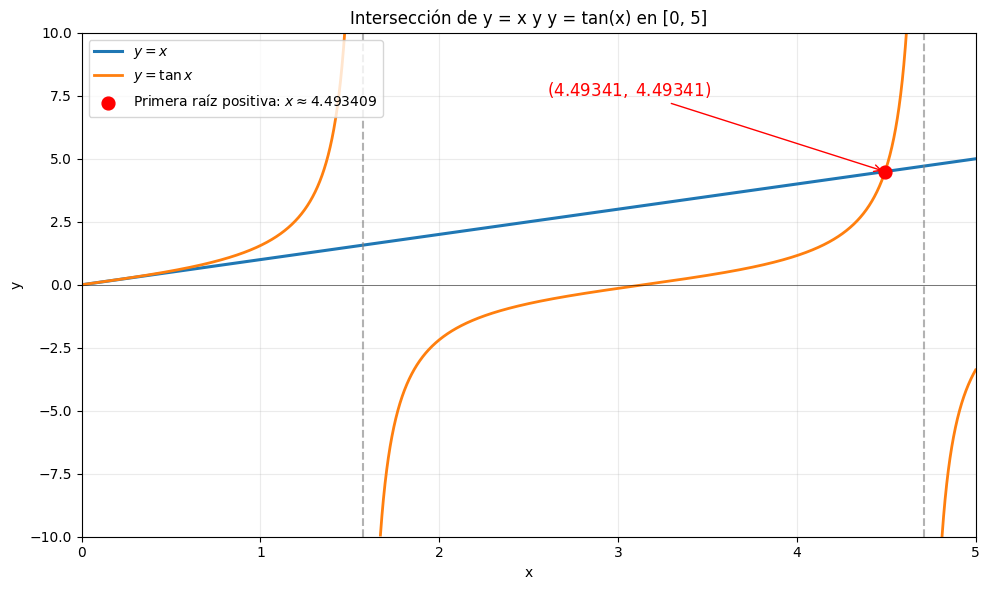

Raíz positiva no trivial marcada: 4.49340945790973


In [12]:
raiz_tan, _ = biseccion(f_tangente, 4.4, 4.6, TOL=1e-12, N0=100)

x = np.linspace(0, 5, 6000)
y_linea = x
y_tan = np.tan(x)
# Ocultar regiones contiguas a polos y valores fuera del rango visible.
y_tan[np.abs(np.cos(x)) < 0.035] = np.nan
y_tan[np.abs(y_tan) > 10] = np.nan

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(x, y_linea, linewidth=2.2, label=r"$y=x$")
ax.plot(x, y_tan, linewidth=2.0, label=r"$y=\tan x$")
ax.scatter([raiz_tan], [raiz_tan], color="red", s=85, zorder=8,
           label=fr"Primera raíz positiva: $x\approx{raiz_tan:.6f}$")
ax.annotate(fr"$({raiz_tan:.5f},\;{raiz_tan:.5f})$",
            xy=(raiz_tan, raiz_tan), xytext=(2.6, 7.5),
            arrowprops=dict(arrowstyle="->", color="red"), color="red", fontsize=12)
ax.axvline(math.pi/2, linestyle="--", color="gray", alpha=0.6)
ax.axvline(3*math.pi/2, linestyle="--", color="gray", alpha=0.6)
ax.axhline(0, color="black", linewidth=0.7, alpha=0.5)
ax.set_xlim(0, 5)
ax.set_ylim(-10, 10)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Intersección de y = x y y = tan(x) en [0, 5]")
ax.grid(True, alpha=0.25)
ax.legend(loc="upper left")
fig.tight_layout()
plt.savefig("grafica_x_tanx.png", dpi=180, bbox_inches="tight")
plt.show()
print("Raíz positiva no trivial marcada:", raiz_tan)


## 10. Resumen de resultados

- $x^3-x-1=0$ en $[1,2]$ y $10^{-4}$: **14** iteraciones por teorema; $p_{14}=1.3247680664$.
- $x^3-7x^2+14x-6=0$ en $[0,1]$, $[1,3.2]$, $[3.2,4]$, con $TOL=10^{-2}$: aproximaciones **0.5859375**, **3.00234375**, **3.41875**; iteraciones **7, 8, 7**.
- $x=2\sin x$ en $[1,2]$: **1.8955001831** con $TOL=10^{-5}$.
- $x=\tan x$ en $[4.4,4.6]$: **4.4934143066** con $TOL=10^{-5}$.
- $x^2-1=e^{1-x^2}$ en $[-2,0]$: **-1.2509765625** con $TOL=10^{-3}$.
- Raíces múltiples en los intervalos indicados: **-3, 0, 1, 3**; no converge en general a la raíz doble $-1$.
- Abrevadero: $h=0.1640625$ cm (parada del Algoritmo 2.1 con $TOL=0.01$); valor refinado $h\approx0.166166$ cm; profundidad refinada $\approx0.833834$ cm.
- Caída con resistencia: $t=14.716796875$ s (parada del Algoritmo 2.1 con $TOL=0.01$); valor refinado $t\approx14.7255$ s.

> Las aproximaciones en el paso de parada pueden diferir del valor refinado, pero ambas cumplen la tolerancia. Esto es esperado: el Algoritmo 2.1 se detiene en cuanto satisface la condición de error, no necesariamente en la mejor aproximación decimal.

### Entrega

1. Ejecutar todas las celdas en Colab: **Entorno de ejecución → Ejecutar todas**.
2. Crear un repositorio público en GitHub.
3. Usar **Archivo → Guardar una copia en GitHub** y elegir el repositorio. Confirmar que se guardaron los resultados.
4. Copiar la dirección del repositorio público y pegarla en el cuestionario.
5. Descargar `grafica_x_tanx.png` desde los archivos de Colab y adjuntarla en la sección de imágenes.